# Diamonds Price Prediction with Linear Regression

**Goal:** predict diamond prices (`price`, in USD) from physical and quality attributes.

**Dataset:** [Diamonds on Kaggle](https://www.kaggle.com/datasets/shivam2503/diamonds) (~54k rows).

## Data dictionary

| Column | Description |
|--------|-------------|
| `carat` | Weight of the diamond |
| `cut` | Cut quality: Fair < Good < Very Good < Premium < Ideal |
| `color` | Color grade from D (best) to J (worst) |
| `clarity` | Clarity grade: I1 (worst) < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF (best) |
| `depth` | Total depth percentage = z / mean(x, y) * 100 |
| `table` | Width of the top of the diamond relative to its widest point (%) |
| `price` | Price in US dollars (target variable) |
| `x` | Length in mm |
| `y` | Width in mm |
| `z` | Depth in mm |

`Unnamed: 0` is only a row index from the original CSV, so it is dropped.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [2]:
dataset=pd.read_csv("data/diamonds.csv")
dataset=dataset.drop(columns=["Unnamed: 0"])
dataset.head(10)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


## 2. Initial inspection

The original file has 53,940 rows and 11 columns. After dropping `Unnamed: 0`,
10 columns remain: 3 categorical (`cut`, `color`, `clarity`) and 7 numeric.
There are no missing values.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [4]:
dataset.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


## 3. Missing values and duplicates

There are no missing values. After dropping `Unnamed: 0`, 146 duplicate rows are found.

In [5]:
print(dataset.isna().sum())

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


In [6]:
print(dataset.duplicated().sum())

146


## 4. Data cleaning

### 4.1 Duplicate rows

The 146 duplicate rows are only about 0.3% of the data. The dataset has no ID column,
so they could be different stones with identical attributes. I removed them anyway,
because a duplicated row could end up in both the train and test sets and make the
test score look better than it really is.

Rows after removing duplicates: 53,794 (from 53,940).

In [7]:
print(dataset.shape)
dataset=dataset.drop_duplicates().reset_index(drop=True)
print(dataset.shape)

(53940, 10)
(53794, 10)


### 4.2 Invalid dimensions

The `describe()` output shows two problems in `x`, `y` and `z`:

- Some rows have a dimension equal to 0, which is physically impossible.
- `y` and `z` have extreme maximum values (58.9 mm and 31.8 mm) compared with their
  75th percentiles (6.54 mm and 4.04 mm).

The largest valid `x` is 10.74 mm, so only rows with all three dimensions between
1 mm and 11 mm were kept.

Rows after cleaning: 53,772 (22 rows removed).

In [8]:
dataset = dataset[
    dataset["x"].between(1, 11) &
    dataset["y"].between(1, 11) &
    dataset["z"].between(1, 11)
].reset_index(drop=True)
print(dataset.shape)

(53772, 10)


## 5. Exploratory data analysis

### 5.1 Price distribution

The distribution of `price` is strongly right-skewed. Almost half of the diamonds cost
less than about $2,000, and the number of stones falls steadily as the price increases,
with a long tail up to about $18,800. This skew is worth remembering when we look at
the residuals later.

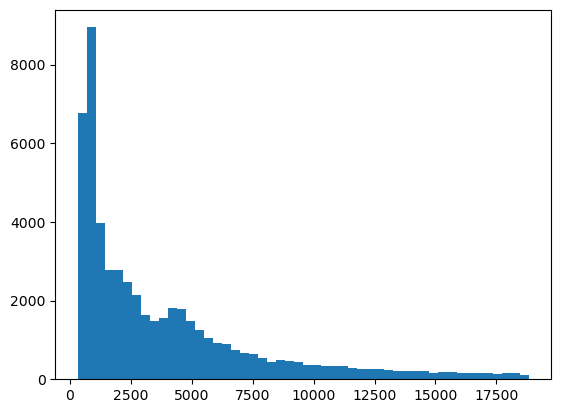

In [9]:
plt.hist(dataset['price'],bins=50)
plt.show()

### 5.2 Carat vs price

Price increases with carat, but the relationship is not a straight line: the curve bends
upward, and the spread of prices grows with carat (around 1 carat, prices range from
roughly $2,500 to over $15,000). Vertical stripes appear at round weights such as 1.0,
1.5 and 2.0 carat, because many stones are cut to round sizes. Prices also stop at about
$18,800, even for stones above 2 carat, so the data looks capped at the top.

A single straight line will not fit this pattern perfectly. We will check this with the
residual plot.

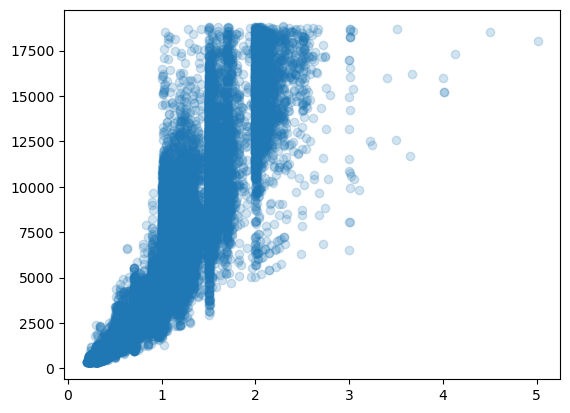

In [10]:
plt.scatter(dataset['carat'],dataset['price'],alpha=0.2)
plt.show()

### 5.3 Correlation between numeric features

- `price` is most strongly correlated with `carat` (0.92), followed by `x` and `y` (0.89)
  and `z` (0.88).
- `depth` (-0.01) and `table` (0.13) have almost no linear correlation with `price`.
- `carat`, `x`, `y` and `z` are almost perfectly correlated with each other (0.98 to 1.0).
  They all describe the size of the stone: a heavier diamond is larger in every dimension.

This is multicollinearity. A linear regression can still predict reasonably well, but the
coefficients of these features become unstable and hard to interpret, because the model
cannot tell which of them is responsible for the change in price.

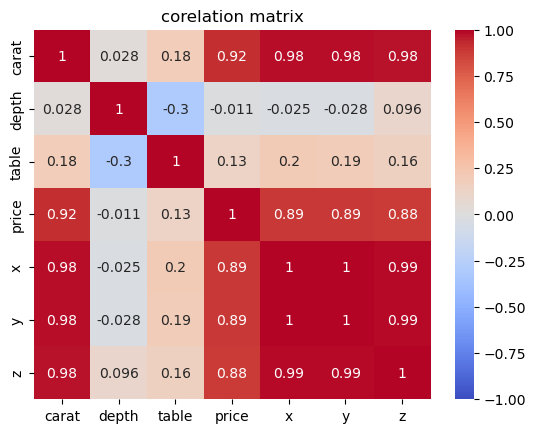

In [11]:
corr=dataset.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm',vmax=1,vmin=-1)
plt.title("corelation matrix")
plt.show()